# Experiment 8 — Strategic algorithm comparison

This experiment compares the two built-in strategic deconfliction policies under identical traffic and known-airspace conditions. `LateralDetourDeconfliction` is specialized in obstacles and geofences; `RecursiveTimeShiftDeconfliction` combines the same lateral airspace avoidance with temporal shifts for UAV–UAV conflicts.

Tactical deconfliction and dynamic hazards are disabled so that execution outcomes reflect only the strategic decisions. For each $N \in \{1, 2, 10, 50, 100\}$, ten paired replications are performed.

In [10]:
import csv
import fcntl
import math
import random
from pathlib import Path
from statistics import fmean

import matplotlib.pyplot as plt
from IPython.display import display

from musas.airspace import Airspace, Box3D, Cylinder3D, Geofence, Obstacle
from musas.algorithms import (
    FirstOrderDynamics, LateralDetourDeconfliction,
    MinimumSeparationConflictPrediction, RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation, SimulationDataset, VisualizationConfig,
    calculate_metrics, plot_dataset,
)

OUTPUT_DIRECTORY = Path("outputs") / "output_exp8"
DATASET_DIRECTORY = OUTPUT_DIRECTORY / "datasets"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_DIRECTORY.mkdir(exist_ok=True)

In [11]:
ALGORITHMS = ("lateral_detour", "recursive_time_shift")
ALGORITHM_LABELS = {
    "lateral_detour": "Lateral detour",
    "recursive_time_shift": "Recursive time shift",
}
N_VALUES = (1, 2, 10, 50, 100)
K = 10
BASE_SEED = 20261009
AREA_HALF_SIZE = 250.0
ALTITUDE_LAYERS = (90.0, 120.0, 150.0)
SIMULATION_END = 220.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 5.0

METRIC_KEYS = (
    "detected_strategic_conflicts", "flights",
    "modified_flights", "rejected_flights",
    "collision_events", "geofence_violations",
    "loss_of_separation_events", "minimum_pairwise_separation",
    "obstacle_violations", "average_planned_distance",
    "average_actual_distance", "average_planned_time",
    "average_actual_time", "average_updates_per_uav",
    "distance_overhead_percent",
)

## Paired strategic scenarios

Each replication contains $N$ random straight routes, three altitude layers, three permanent obstacles and two known geofences. Every restriction is present before proposals are submitted.

In [12]:
def create_airspace():
    airspace = Airspace()
    for obstacle in (
        Obstacle("central-building", Box3D(-35, 25, -55, 15, 0, 115)),
        Obstacle("east-tower", Cylinder3D(95, 55, 20, 0, 145)),
        Obstacle("west-block", Box3D(-155, -105, -5, 55, 0, 105)),
    ):
        airspace.add_obstacle(obstacle)
    for geofence in (
        Geofence("hospital-zone", Cylinder3D(-75, 105, 35, 60, 170)),
        Geofence("stadium-zone", Cylinder3D(80, -95, 40, 60, 170)),
    ):
        airspace.add_geofence(geofence)
    return airspace


def point_on_border(rng, border):
    coordinate = rng.uniform(-AREA_HALF_SIZE, AREA_HALF_SIZE)
    return {
        "left": (-AREA_HALF_SIZE, coordinate),
        "right": (AREA_HALF_SIZE, coordinate),
        "bottom": (coordinate, -AREA_HALF_SIZE),
        "top": (coordinate, AREA_HALF_SIZE),
    }[border]


def create_flight_plans(number_of_uavs, seed):
    rng = random.Random(seed)
    borders = ("left", "right", "bottom", "top")
    plans = {}
    for index in range(number_of_uavs):
        while True:
            start_border = rng.choice(borders)
            end_border = rng.choice([item for item in borders if item != start_border])
            start = point_on_border(rng, start_border)
            end = point_on_border(rng, end_border)
            if math.dist(start, end) >= 260.0:
                break
        altitude = rng.choice(ALTITUDE_LAYERS)
        departure = rng.uniform(4.0, 20.0)
        plans[f"UAV {index + 1:02d}"] = FlightPlan([
            Waypoint(*start, altitude, departure),
            Waypoint(*end, altitude, departure + 80.0),
        ])
    return plans

In [13]:
def run_simulation(algorithm_name, number_of_uavs, replication):
    seed = BASE_SEED + 1000 * number_of_uavs + replication
    dataset_path = (
        DATASET_DIRECTORY
        / f"{algorithm_name}_n_{number_of_uavs:03d}_run_{replication + 1:02d}.sqlite"
    )
    predictor = MinimumSeparationConflictPrediction(
        minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
        sampling_interval=0.75,
    )
    lateral = LateralDetourDeconfliction(
        conflict_prediction_algorithm=predictor,
        lateral_clearance=12.0, maximum_detours=6,
    )
    if algorithm_name == "lateral_detour":
        deconfliction = lateral
    elif algorithm_name == "recursive_time_shift":
        deconfliction = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=predictor,
            time_shift_step=4.0, maximum_iterations=40,
            airspace_deconfliction_algorithm=lateral,
        )
    else:
        raise ValueError(f"Unknown algorithm: {algorithm_name}")

    simulation = Simulation(
        airspace=create_airspace(),
        strategic_conflict_prediction_algorithm=predictor,
        strategic_deconfliction_algorithm=deconfliction,
        flight_update_interval=0.2, trajectory_record_interval=0.5,
        message_types_to_log=(), dataset_path=dataset_path,
        overwrite_dataset=True, keep_history_in_memory=False,
        dataset_metadata={
            "experiment": "strategic_algorithm_comparison",
            "algorithm": algorithm_name, "number_of_uavs": number_of_uavs,
            "replication": replication + 1, "seed": seed,
        },
    )
    for index, (name, plan) in enumerate(
        create_flight_plans(number_of_uavs, seed).items()
    ):
        simulation.add_uav(
            name=name, flight_plan=plan,
            dynamics_algorithm=FirstOrderDynamics(100.0, 0.0),
            guidance_algorithm=WaypointGuidance(0.0, 12.0),
            submission_time=index * 0.03, waypoint_acceptance_radius=1.0,
        )
    simulation.run(until=SIMULATION_END)
    simulation.close()

    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset, MINIMUM_SEPARATION_DISTANCE, COLLISION_DISTANCE,
        )
    metrics["average_updates_per_uav"] = fmean(
        values["updates"] for values in metrics["per_uav"].values()
    )
    started_flights = [
        values for values in metrics["per_uav"].values()
        if values["actual_distance"] is not None
    ]
    planned = (
        fmean(values["planned_distance"] for values in started_flights)
        if started_flights else None
    )
    actual = (
        fmean(values["actual_distance"] for values in started_flights)
        if started_flights else None
    )
    metrics["distance_overhead_percent"] = (
        None if planned in (None, 0) or actual is None
        else 100.0 * (actual - planned) / planned
    )
    return {
        "algorithm": algorithm_name, "number_of_uavs": number_of_uavs,
        "replication": replication + 1,
        "seed": seed, **{key: metrics[key] for key in METRIC_KEYS},
    }

In [14]:
def execute_experiment():
    with (OUTPUT_DIRECTORY / "experiment.lock").open("w") as lock_file:
        try:
            fcntl.flock(lock_file, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError as error:
            raise RuntimeError("Experiment 8 is already running") from error
        results = []
        for algorithm_name in ALGORITHMS:
            for number_of_uavs in N_VALUES:
                for replication in range(K):
                    print(
                        f"{ALGORITHM_LABELS[algorithm_name]:20s} | "
                        f"N={number_of_uavs:3d} | "
                        f"replication={replication + 1:02d}/{K}", end="\r",
                    )
                    results.append(
                        run_simulation(algorithm_name, number_of_uavs, replication)
                    )
                print(
                    f"{ALGORITHM_LABELS[algorithm_name]:20s} | "
                    f"N={number_of_uavs:3d} completed"
                )
        return results

results = execute_experiment()
raw_path = OUTPUT_DIRECTORY / "replication_metrics.csv"
with raw_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=results[0].keys())
    writer.writeheader(); writer.writerows(results)
print("Saved:", raw_path)

Lateral detour       | N=  1 completedtion=10/10
Lateral detour       | N=  2 completedtion=10/10
Lateral detour       | N= 10 completedtion=10/10
Lateral detour       | N= 50 completedtion=10/10
Lateral detour       | N=100 completedtion=10/10
Recursive time shift | N=  1 completedtion=10/10
Recursive time shift | N=  2 completedtion=10/10
Recursive time shift | N= 10 completedtion=10/10
Recursive time shift | N= 50 completedtion=10/10
Recursive time shift | N=100 completedtion=10/10
Saved: outputs/output_exp8/replication_metrics.csv


## Mean results

Because lateral detour deliberately does not resolve traffic conflicts, its rejection rate is part of the comparison rather than an implementation failure.

In [15]:
def mean_defined(values):
    values = [value for value in values if value is not None]
    return fmean(values) if values else None

mean_metrics = []
for algorithm_name in ALGORITHMS:
    for number_of_uavs in N_VALUES:
        group = [
            row for row in results
            if row["algorithm"] == algorithm_name
            and row["number_of_uavs"] == number_of_uavs
        ]
        mean_metrics.append({
            "algorithm": algorithm_name,
            "number_of_uavs": number_of_uavs,
            **{key: mean_defined([row[key] for row in group]) for key in METRIC_KEYS},
        })
summary_path = OUTPUT_DIRECTORY / "mean_metrics.csv"
with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=mean_metrics[0].keys())
    writer.writeheader(); writer.writerows(mean_metrics)

print(f"{'Algorithm':<22} {'N':>4} {'conflicts':>10} {'modified':>9} {'rejected':>9} {'LOS':>7} {'coll.':>7} {'geof.':>7} {'obst.':>7} {'min.sep.':>9} {'extra %':>9}")
for row in mean_metrics:
    minimum = row["minimum_pairwise_separation"]
    minimum_text = "n/a" if minimum is None else f"{minimum:.2f}"
    print(
        f"{ALGORITHM_LABELS[row['algorithm']]:<22} "
        f"{row['number_of_uavs']:4d} "
        f"{row['detected_strategic_conflicts']:10.2f} "
        f"{row['modified_flights']:9.2f} {row['rejected_flights']:9.2f} "
        f"{row['loss_of_separation_events']:7.2f} {row['collision_events']:7.2f} "
        f"{row['geofence_violations']:7.2f} {row['obstacle_violations']:7.2f} "
        f"{minimum_text:>9} "
        f"{row['distance_overhead_percent']:9.2f}"
    )
print("Saved:", summary_path)

Algorithm                 N  conflicts  modified  rejected     LOS   coll.   geof.   obst.  min.sep.   extra %
Lateral detour            1       0.20      0.20      0.00    0.00    0.00    0.00    0.00       n/a     -0.32
Lateral detour            2       0.60      0.60      0.00    0.00    0.00    0.00    0.00    160.39      0.43
Lateral detour           10       6.70      3.50      1.70    0.00    0.00    0.00    0.00     32.36      2.53
Lateral detour           50      58.00      8.30     25.80    0.00    0.00    0.00    0.10     30.02      1.93
Lateral detour          100     148.00     10.00     65.30    0.00    0.00    0.00    0.00     30.08      1.07
Recursive time shift      1       0.20      0.20      0.00    0.00    0.00    0.00    0.00       n/a     -0.32
Recursive time shift      2       0.60      0.60      0.00    0.00    0.00    0.00    0.00    160.39      0.43
Recursive time shift     10       6.80      5.40      0.00    0.00    0.00    0.00    0.00     30.91      1.72
R

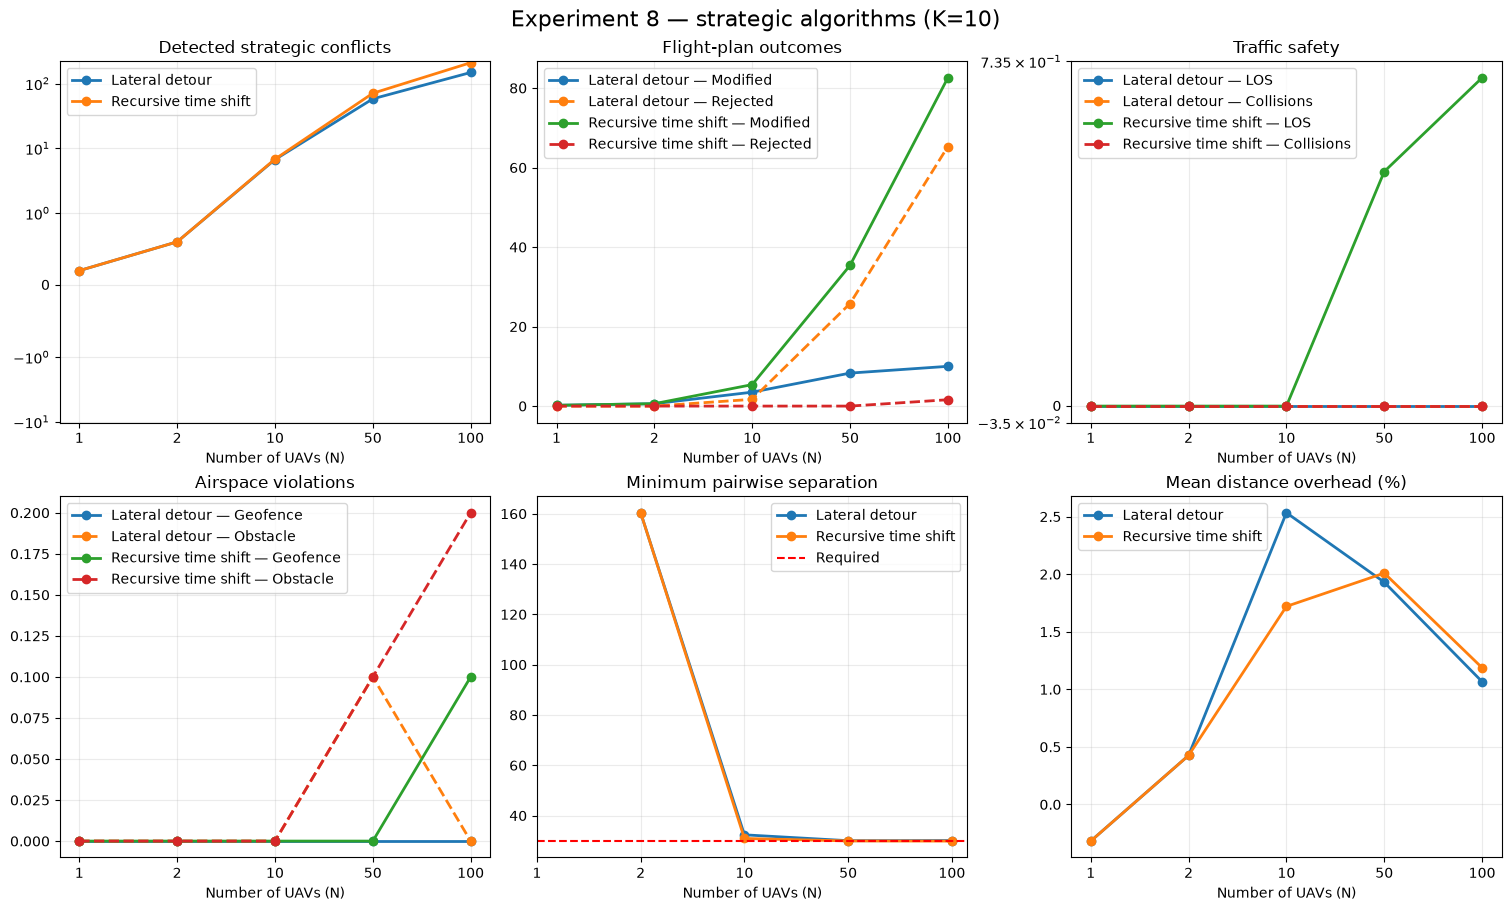

Saved: outputs/output_exp8/mean_metrics.png


In [16]:
x = range(len(N_VALUES))
figure, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

def lines(axis, keys, names, title, log=False):
    for algorithm_name in ALGORITHMS:
        rows = [
            row for row in mean_metrics
            if row["algorithm"] == algorithm_name
        ]
        for index, (key, name) in enumerate(zip(keys, names)):
            label = ALGORITHM_LABELS[algorithm_name]
            if len(keys) > 1:
                label = f"{label} — {name}"
            axis.plot(
                x, [row[key] for row in rows], marker="o",
                linewidth=2, linestyle="-" if index == 0 else "--",
                label=label,
            )
    axis.set_title(title); axis.set_xticks(list(x), N_VALUES)
    axis.set_xlabel("Number of UAVs (N)")
    axis.grid(alpha=0.25)
    if log: axis.set_yscale("symlog", linthresh=1.0)
    axis.legend()

lines(axes[0, 0], ("detected_strategic_conflicts",), ("Conflicts",), "Detected strategic conflicts", True)
lines(axes[0, 1], ("modified_flights", "rejected_flights"), ("Modified", "Rejected"), "Flight-plan outcomes")
lines(axes[0, 2], ("loss_of_separation_events", "collision_events"), ("LOS", "Collisions"), "Traffic safety", True)
lines(axes[1, 0], ("geofence_violations", "obstacle_violations"), ("Geofence", "Obstacle"), "Airspace violations")
lines(axes[1, 1], ("minimum_pairwise_separation",), ("Minimum separation",), "Minimum pairwise separation")
axes[1, 1].axhline(MINIMUM_SEPARATION_DISTANCE, color="red", linestyle="--", label="Required")
axes[1, 1].legend()
lines(axes[1, 2], ("distance_overhead_percent",), ("Extra distance",), "Mean distance overhead (%)")
figure.suptitle(f"Experiment 8 — strategic algorithms (K={K})", fontsize=16)
figure_path = OUTPUT_DIRECTORY / "mean_metrics.png"
figure.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show(); print("Saved:", figure_path)

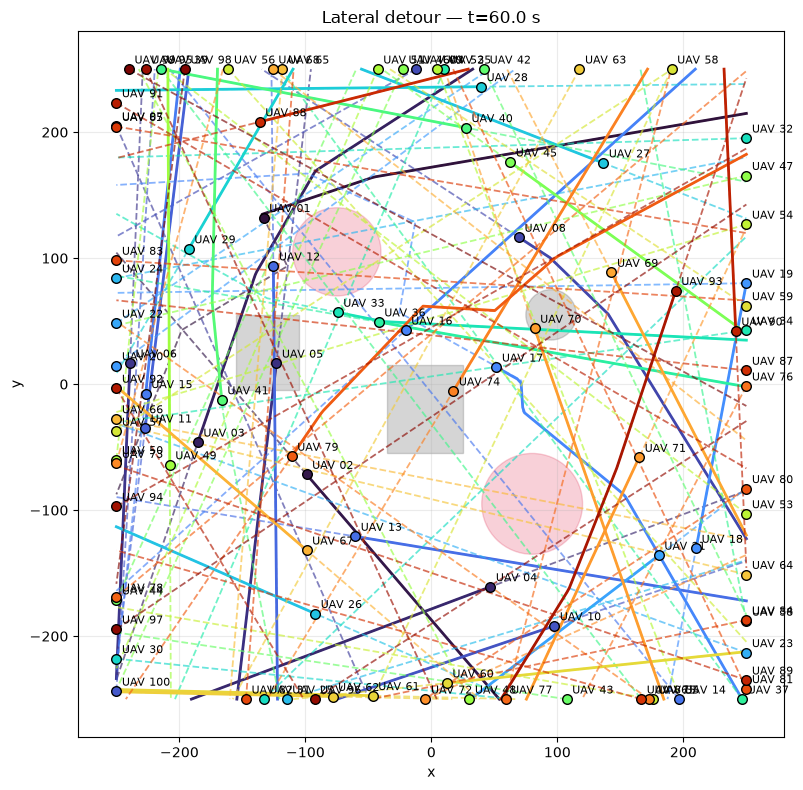

Saved: outputs/output_exp8/lateral_detour_n_100_t60.png


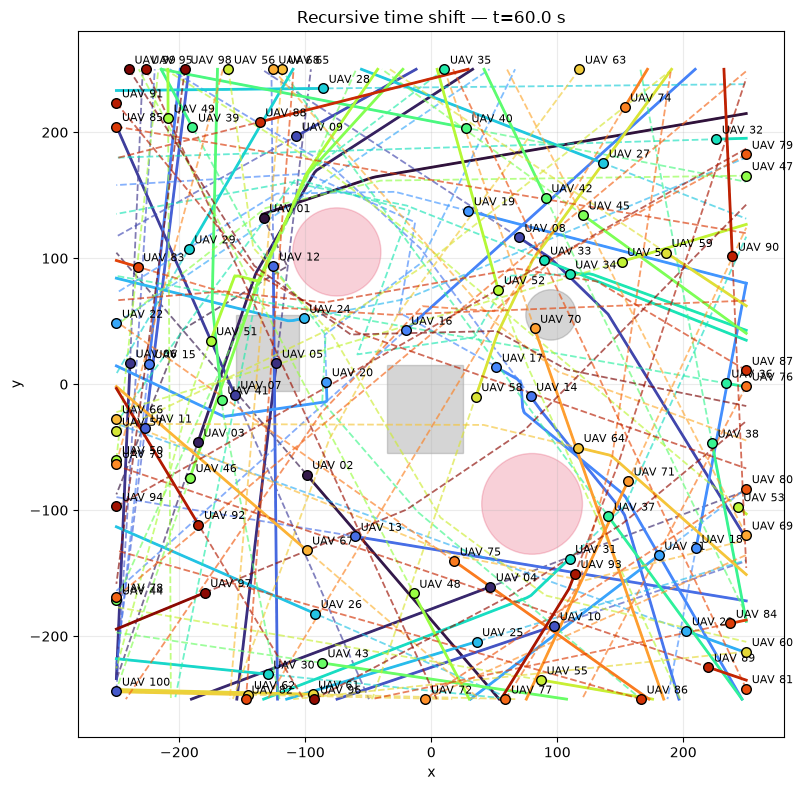

Saved: outputs/output_exp8/recursive_time_shift_n_100_t60.png


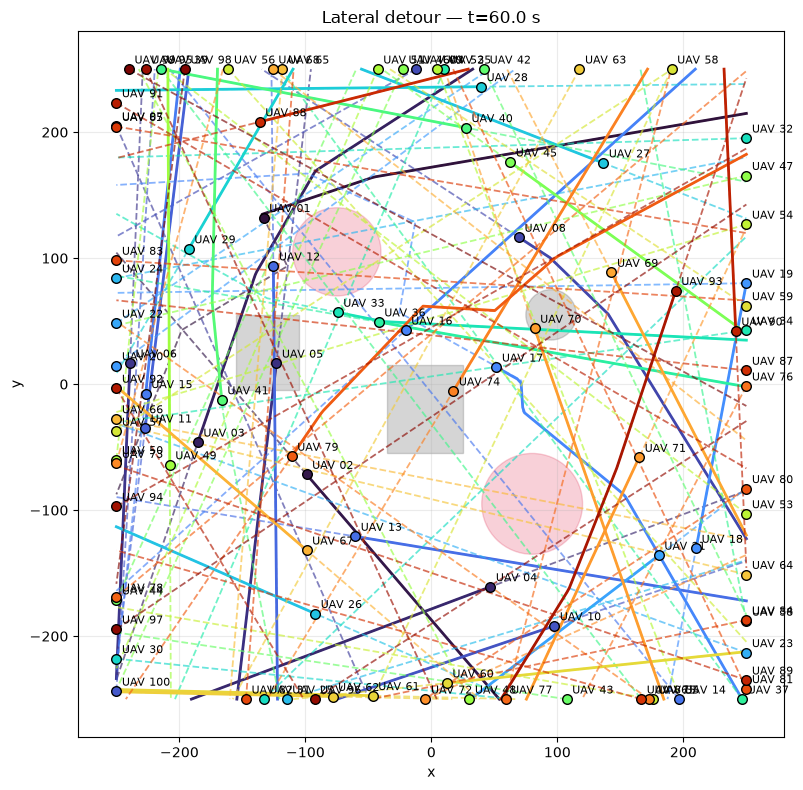

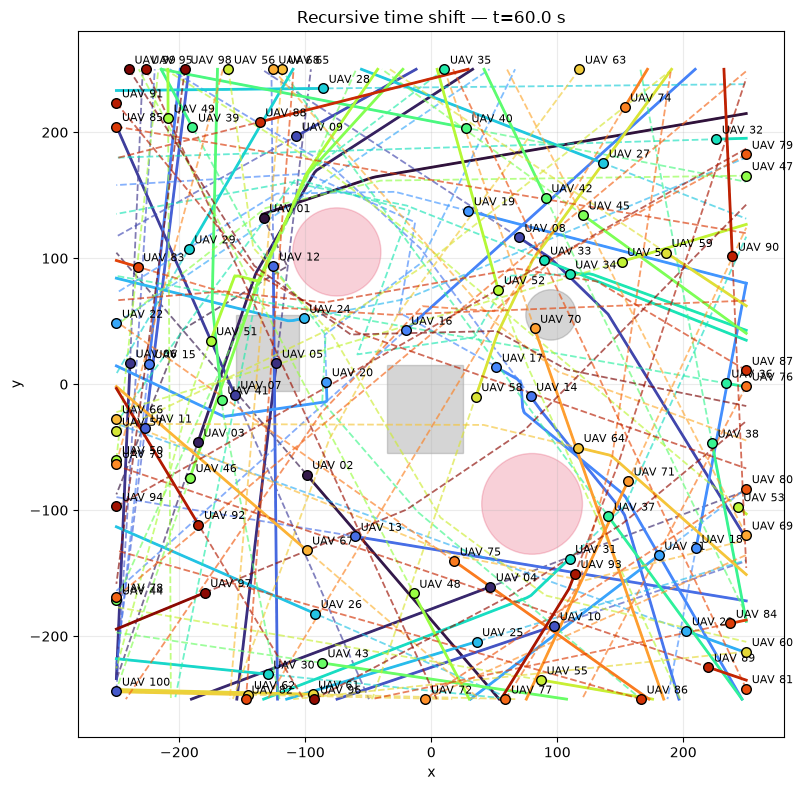

In [17]:
for algorithm_name in ALGORITHMS:
    dataset_path = DATASET_DIRECTORY / f"{algorithm_name}_n_100_run_01.sqlite"
    image_path = OUTPUT_DIRECTORY / f"{algorithm_name}_n_100_t60.png"
    figure = plot_dataset(
        dataset_path=dataset_path, timestamp=60.0, output_path=image_path,
        config=VisualizationConfig(
            uav_names=None, view="xy", show_real_trajectories=True,
            show_current_positions=True, show_flight_plans=True,
            show_tracks=False, show_geofences=True,
            show_wind_zones=False, show_obstacles=True,
            show_legend=False, figure_size=(10.0, 8.0),
            title=ALGORITHM_LABELS[algorithm_name],
        ),
    )
    display(figure); print("Saved:", image_path)